# Notebook 05 — TSP cerrado: QUBO/QAOA frente a solvers clásicos (capitales de Colombia)

## Diseño del experimento

Todos los solvers resuelven **el mismo problema** y se puntúan con **la misma función**: la longitud $L(\pi)=\sum_k D_{\pi_k,\pi_{k+1}}$ de un tour cerrado
de un único vehículo (no es VRP) sobre la matriz de distancias haversine $D$ entre capitales colombianas.

| | Fuerza bruta | NN / NN+2-opt | SA-QUBO | QAOA ($p=1$) |
|---|---|---|---|---|
| **Garantía** | Óptimo exacto, $(n-1)!$ | Heurística | Heurística sobre el QUBO | Heurística variacional |
| **Variables** | — | — | $(n-1)^2$ binarias (depósito fijo) | $(n-1)^2$ qubits |
| **Referencia** | Óptimo | Clásico fuerte | QUBO de Lucas | QUBO de Lucas |

**Formulación.** Con el depósito (Bogotá) fijo en la posición 0, la variable $x_{i,p}=1$ indica que la ciudad $i$ ocupa la posición $p$
($i,p=1,\dots,n-1$). El QUBO de Lucas penaliza que una posición tenga más o menos de una ciudad y que una ciudad aparezca más o menos de una vez,
y añade la longitud del tour como objetivo. Para $n=4$ son 9 variables, es decir, 9 qubits.

**Nota sobre la versión anterior.** El cuaderno original codificaba las $n^2=16$ variables sin fijar el depósito y puntuaba QAOA con la energía de Ising,
con bitstrings habitualmente infactibles. Esa codificación de 16 qubits no se puede reejecutar con el simulador de vector de estados actual
(la evolución densa pide 64 GiB). Este cuaderno usa el protocolo común `qml_v2.tsp_optimization`, que el Capítulo 5 de la tesis cita.

## 1. Configuración

In [1]:
import sys
import time
import math
import warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve()))

import qiskit
from qiskit_optimization.converters import QuadraticProgramToQubo
from qml_v2 import tsp_optimization as tsp

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 11})

OUT_METRICS = Path("../data/output/metrics")
OUT_FIGURES = Path("../data/output/figures")
OUT_FIGURES.mkdir(parents=True, exist_ok=True)

N_QUBO = 4           # ciudades del subproblema cuántico: (4-1)^2 = 9 qubits
QAOA_P = 1
QAOA_RESTARTS = 3
QAOA_MAXITER = 80
SA_ITERS = 5000
SEED = 42
print("Qiskit", qiskit.__version__)

Qiskit 2.6.1


## 2. Datos — capitales colombianas (coordenadas reales) y distancias haversine

In [2]:
cities_df = pd.DataFrame(tsp.COLOMBIA_CITIES, columns=["ciudad", "latitud", "longitud"])
D_full, names_full = tsp.make_instance("colombia", len(cities_df), SEED)
print(cities_df.to_string(index=False))
print(f"\nDistancia media entre pares: {D_full[D_full > 0].mean():.0f} km (haversine, R = 6371.0088 km)")

       ciudad  latitud  longitud
       Bogotá   4.7110  -74.0721
     Medellín   6.2476  -75.5658
         Cali   3.4516  -76.5320
 Barranquilla  10.9685  -74.7813
    Cartagena  10.3910  -75.4794
       Cúcuta   7.8891  -72.4967
  Bucaramanga   7.1193  -73.1227
      Pereira   4.8133  -75.6961
    Manizales   5.0700  -75.5138
       Ibagué   4.4389  -75.2322
Villavicencio   4.1420  -73.6266
  Santa Marta  11.2408  -74.1990

Distancia media entre pares: 418 km (haversine, R = 6371.0088 km)


## 3. Grafo de ciudades

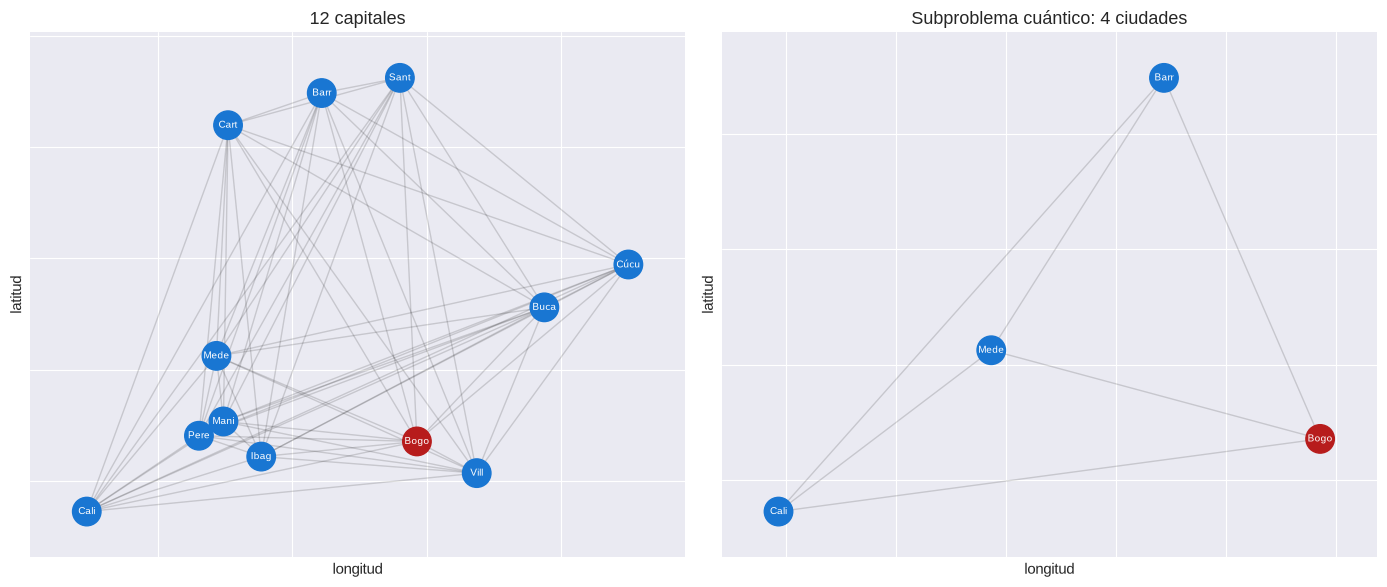

In [3]:
pos = {i: (cities_df.longitud[i], cities_df.latitud[i]) for i in range(len(cities_df))}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, n, titulo in ((axes[0], len(cities_df), f"{len(cities_df)} capitales"),
                      (axes[1], N_QUBO, f"Subproblema cuántico: {N_QUBO} ciudades")):
    G = nx.complete_graph(n)
    nx.draw_networkx_edges(G, {i: pos[i] for i in range(n)}, ax=ax, alpha=0.15)
    nx.draw_networkx_nodes(G, {i: pos[i] for i in range(n)}, ax=ax, node_size=420,
                           node_color=["#B71C1C"] + ["#1976D2"] * (n - 1))
    nx.draw_networkx_labels(G, {i: pos[i] for i in range(n)}, labels={i: cities_df.ciudad[i][:4] for i in range(n)},
                            ax=ax, font_size=7, font_color="white")
    ax.set_title(titulo)
    ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
plt.tight_layout()
plt.savefig(OUT_FIGURES / "05_tsp_grafo_ciudades.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Solvers clásicos

Sobre las 12 capitales solo se pueden ejecutar los heurísticos (el exacto $(n-1)!=39\,916\,800$ tours queda fuera de este cuaderno).
Sobre el subproblema de 4 ciudades se ejecuta además la fuerza bruta, que fija el óptimo.

In [4]:
def medir(funcion, *args, **kw):
    t0 = time.perf_counter(); r = funcion(*args, **kw); return r, time.perf_counter() - t0

nn12, t = medir(tsp.nearest_neighbor, D_full)
nn2opt12, t2 = medir(tsp.nn_plus_two_opt, D_full)
print(f"12 ciudades — NN: {tsp.tour_length(D_full, nn12):.1f} km | NN+2-opt: {tsp.tour_length(D_full, nn2opt12):.1f} km")

D4, names4 = tsp.make_instance("colombia", N_QUBO, SEED)
exacto, t_exacto = medir(tsp.brute_force_tsp, D4)
nn4, t_nn = medir(tsp.nearest_neighbor, D4)
nnms4, t_nnms = medir(tsp.nearest_neighbor_multistart, D4)
opt4, t_opt = medir(tsp.nn_plus_two_opt, D4)
rnd4, t_rnd = medir(tsp.random_tour, D4)
L_exacto = tsp.tour_length(D4, exacto)
print(f"\n{N_QUBO} ciudades — óptimo exacto: {L_exacto:.1f} km  {tsp.format_tour(exacto, names4)}")

12 ciudades — NN: 2564.1 km | NN+2-opt: 2230.6 km

4 ciudades — óptimo exacto: 1867.6 km  Bogotá → Cali → Medellín → Barranquilla → Bogotá


## 5. Formulación QUBO (Lucas, depósito fijo)

In [5]:
qp = tsp.build_tsp_qp(D4, fix_depot=True)
qubo = QuadraticProgramToQubo().convert(qp)
print(f"Variables binarias: {qp.get_num_binary_vars()}  |  qubits QAOA: {qubo.get_num_vars()}")

Variables binarias: 9  |  qubits QAOA: 9


## 6. QAOA ($p=1$, 3 reinicios COBYLA de 80 evaluaciones)

El coste que se reporta es la longitud del tour decodificado, **nunca** la energía de Ising; si ningún reinicio produce un tour factible, el resultado se declara no factible.

In [6]:
ruta_qaoa, t_qaoa = tsp.qaoa_tsp(D4, p=QAOA_P, maxiter=QAOA_MAXITER, restarts=QAOA_RESTARTS,
                                  fix_depot=True, random_state=SEED)
factible = tsp.is_valid_tour(ruta_qaoa, N_QUBO)
L_qaoa = tsp.tour_length(D4, ruta_qaoa) if factible else float("nan")
print(f"Tour QAOA : {tsp.format_tour(ruta_qaoa, names4) if factible else 'no factible'}")
print(f"Longitud  : {L_qaoa:.1f} km  (exacto {L_exacto:.1f} km)")
print(f"Tiempo    : {t_qaoa:.1f} s")

Tour QAOA : Bogotá → Barranquilla → Medellín → Cali → Bogotá
Longitud  : 1867.6 km  (exacto 1867.6 km)
Tiempo    : 200.8 s


## 7. SA-QUBO (recocido simulado clásico sobre el mismo QUBO)

Es el análogo clásico de un *quantum annealer*; se ejecuta sobre el mismo QUBO de 9 variables y se puntúa con la longitud del tour decodificado.

In [7]:
t0 = time.perf_counter()
ruta_sa, energia_sa = tsp.sa_qubo_tsp(D4, fix_depot=True, n_iters=SA_ITERS, T0=1.0, random_state=SEED)
t_sa = time.perf_counter() - t0
L_sa = tsp.tour_length(D4, ruta_sa) if tsp.is_valid_tour(ruta_sa, N_QUBO) else float("nan")
print(f"SA-QUBO: {L_sa:.1f} km  (energía QUBO {energia_sa:.1f}; {t_sa:.2f} s)")


SA-QUBO: 1867.6 km  (energía QUBO -54320.4; 0.20 s)


## 8. Comparación

             solver  longitud_km  tiempo_s  gap_vs_exacto_%
BruteForce (exacto)       1867.6    0.0000             0.00
           NN+2-opt       1867.6    0.0000             0.00
            QAOA-p1       1867.6  200.8387             0.00
            SA-QUBO       1867.6    0.2043             0.00
     NN multi-start       1934.2    0.0000             3.57
   Nearest Neighbor       2124.6    0.0000            13.76
     Tour aleatorio       2124.6    0.0003            13.76


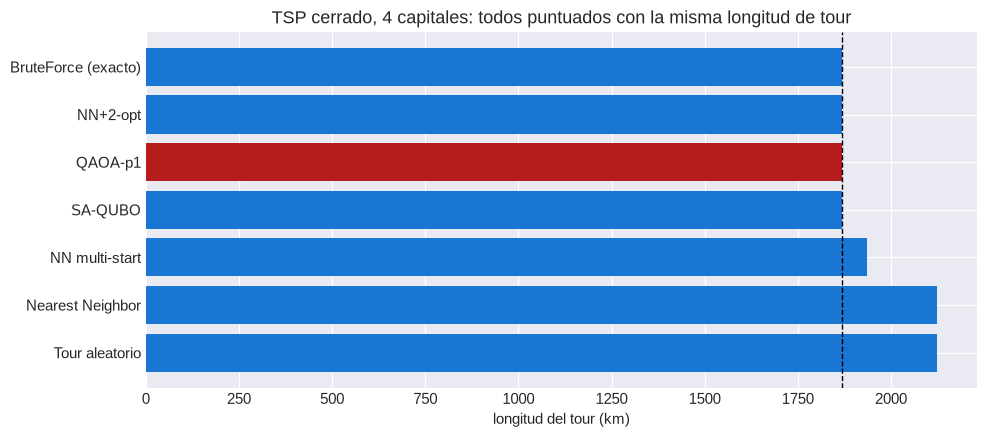

In [8]:
filas = [
    ("BruteForce (exacto)", L_exacto, t_exacto),
    ("NN+2-opt", tsp.tour_length(D4, opt4), t_opt),
    ("QAOA-p1", L_qaoa, t_qaoa),
    ("SA-QUBO", L_sa, t_sa),
    ("NN multi-start", tsp.tour_length(D4, nnms4), t_nnms),
    ("Nearest Neighbor", tsp.tour_length(D4, nn4), t_nn),
    ("Tour aleatorio", tsp.tour_length(D4, rnd4), t_rnd),
]
res = pd.DataFrame(filas, columns=["solver", "longitud_km", "tiempo_s"])
res["gap_vs_exacto_%"] = 100 * (res.longitud_km - L_exacto) / L_exacto
print(res.round({"longitud_km": 1, "tiempo_s": 4, "gap_vs_exacto_%": 2}).to_string(index=False))
res.to_csv(OUT_METRICS / "05_tsp_resultados.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["#B71C1C" if s == "QAOA-p1" else "#1976D2" for s in res.solver]
ax.barh(res.solver, res.longitud_km, color=colores)
ax.axvline(L_exacto, color="k", ls="--", lw=1)
ax.set_xlabel("longitud del tour (km)"); ax.invert_yaxis()
ax.set_title("TSP cerrado, 4 capitales: todos puntuados con la misma longitud de tour")
plt.tight_layout(); plt.savefig(OUT_FIGURES / "05_tsp_comparacion_solvers.png", dpi=130, bbox_inches="tight"); plt.show()

## 9. Recursos: coste de la fuerza bruta frente a los qubits de la codificación

La fuerza bruta se mide hasta $n=9$ y se extrapola linealmente en $(n-1)!$ para $n>9$; las filas extrapoladas son **estimaciones**, no mediciones.
La codificación cuántica necesita $(n-1)^2$ qubits.

In [9]:
filas = []
for n in range(3, 10):
    Dn, _ = tsp.make_instance("colombia", n, SEED)
    _, t = medir(tsp.brute_force_tsp, Dn)
    filas.append((n, math.factorial(n - 1), t, (n - 1) ** 2, "medido"))
t_perm = filas[-1][2] / filas[-1][1]
for n in (10, 12, 15, 20):
    filas.append((n, math.factorial(n - 1), t_perm * math.factorial(n - 1), (n - 1) ** 2, "extrapolado"))
esc = pd.DataFrame(filas, columns=["n", "tours", "t_fuerza_bruta_s", "qubits_QAOA", "origen"])
print(esc.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

 n              tours  t_fuerza_bruta_s  qubits_QAOA      origen
 3                  2           1.7e-05            4      medido
 4                  6             1e-05            9      medido
 5                 24          2.97e-05           16      medido
 6                120          0.000146           25      medido
 7                720          0.000901           36      medido
 8               5040           0.00705           49      medido
 9              40320            0.0602           64      medido
10             362880             0.542           81 extrapolado
12           39916800              59.6          121 extrapolado
15        87178291200           1.3e+05          196 extrapolado
20 121645100408832000          1.82e+11          361 extrapolado


## 10. Lectura

* En Colombia con $n=4$ la fuerza bruta, NN+2-opt, QAOA-$p=1$ y SA-QUBO obtienen el mismo tour de longitud mínima; el Nearest Neighbor simple queda un 13.8 % por encima. A esta escala no hay ventaja de tiempo: el exacto y el 2-opt tardan menos de un milisegundo.
* QAOA solo cuenta como solución si el bitstring más probable decodifica un tour factible; el coste es la longitud del tour, no la energía de Ising.
* Lo que aporta el caso es metodológico: misma matriz $D$, misma métrica, tours factibles y un QUBO de $(n-1)^2$ variables. No hay evidencia de ventaja cuántica.
* Para $n\gtrsim 20$ los heurísticos clásicos (LKH, 2-opt, recocido) dominan en calidad y tiempo; el simulador de vector de estados no llega a esa escala.
* Las medias sobre varias instancias (réplicas Euclidean, Colombia) se calculan con `python -m qml_v2.tsp_optimization` y alimentan el Capítulo 5.